# Our approach — Llama 3.3 70B on StrategyClaim (500 claims, annotators' facts)

The 500-claim experimental split of the ArgLLM repository, with the annotators' facts. Pipeline, results and example frameworks. Results: credulous 90.2, skeptical 91.2, net support 88.2, 1.6% of claims with more than one extension.

Run on Kaggle; the API key is read from Kaggle secrets (`OPENROUTER_API_KEY`). Outputs are kept so the reported numbers can be checked.

In [1]:
!pip install -q openai datasets scikit-learn

import os, re, json, time, pickle, shutil
from pathlib import Path
from itertools import combinations
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
from openai import OpenAI
from kaggle_secrets import UserSecretsClient
from datasets import load_from_disk
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
from IPython.display import FileLink, display

WORK_DIR = Path("/kaggle/working/llama_strategyclaim_v2")
WORK_DIR.mkdir(parents=True, exist_ok=True)

key = UserSecretsClient().get_secret("OPENROUTER_API_KEY")
client = OpenAI(api_key=key,
                base_url="https://openrouter.ai/api/v1",
                timeout=180)
MODEL_NAME = "meta-llama/llama-3.3-70b-instruct"

repo = "/kaggle/working/argumentative-llms"
if not Path(repo).exists():
    os.system("cd /kaggle/working && git clone -q "
              "https://github.com/CLArg-group/argumentative-llms.git")
df = load_from_disk(repo + "/Datasets/StrategyQA/Experiment")
df = df.to_pandas().reset_index(drop=True)


def format_facts(f):
    if f is None:
        return ""
    if isinstance(f, (list, tuple, np.ndarray)):
        return "\n".join(f"- {str(x)}" for x in f)
    return str(f)


baf_df = pd.DataFrame({
    "example_index": range(len(df)),
    "claim": df["claim"].astype(str),
    "facts_text": df["facts"].apply(format_facts),
    "gold": df["valid"].apply(lambda v: int(bool(v))),
})
print("claims:", len(baf_df), "| true:", baf_df["gold"].sum())

r = client.chat.completions.create(
    model=MODEL_NAME, temperature=0, max_tokens=10,
    messages=[{"role": "user",
               "content": "Is Paris in France? Answer true or false."}])
print("test:", r.choices[0].message.content)

claims: 500 | true: 250
test: True.


In [2]:
BAF_CONFIG = {
    "n_pro_candidates": 5, "n_con_candidates": 5,
    "max_pro_keep": 4, "max_con_keep": 4,
    "min_relevance": 0.60, "min_grounding": 0.55,
    "min_clarity": 0.60, "min_quality": 0.58,
    "min_target_match": 0.65, "min_grounding_edge": 0.55,
    "min_relation_score": 0.68,
    "max_conflict_pairs": 3, "max_claim_attacks": 2,
    "audit_batch_size": 16,
    "generation_temperature": 0.15, "audit_temperature": 0.0,
    "max_retries": 5,
}

SYSTEM = ("You are an expert in claim verification, formal "
          "argumentation and strict JSON output.")


def clip01(v):
    try:
        return max(0.0, min(1.0, float(v)))
    except Exception:
        return 0.0


def extract_json_object(text):
    text = str(text or "").strip()
    text = re.sub(r"```(?:json)?", "", text, flags=re.IGNORECASE)
    text = text.strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass
    s, e = text.find("{"), text.rfind("}")
    if s >= 0 and e > s:
        return json.loads(text[s:e + 1])
    raise ValueError("No JSON")


def json_call(prompt, temperature, max_tokens, retries=8):
    last = None
    for a in range(1, retries + 1):
        try:
            resp = client.chat.completions.create(
                model=MODEL_NAME,
                messages=[{"role": "system", "content": SYSTEM},
                          {"role": "user", "content": prompt}],
                temperature=temperature, max_tokens=max_tokens)
            t = resp.choices[0].message.content
            if not t:
                raise ValueError("empty")
            return extract_json_object(t)
        except Exception as e:
            last = e
            msg = str(e)
            if "402" in msg:
                raise RuntimeError("no OpenRouter credit left")
            busy = any(c in msg for c in ["429", "502", "503", "504"])
            if busy or "rate" in msg.lower():
                time.sleep(20 * a)
            else:
                time.sleep(3 * a)
    raise RuntimeError(f"failed: {last}")


def generate_and_score_arguments(claim, facts_text, config=BAF_CONFIG):
    prompt = f"""
Construct candidate arguments for a Bipolar Argumentation Framework used for claim verification.

CLAIM:
{claim}

AVAILABLE FACTS:
{facts_text}

First determine the intended meaning of the claim, then reason carefully from facts and commonsense.

Generate up to {config["n_pro_candidates"]} PRO candidates and up to {config["n_con_candidates"]} CON candidates.

PRO: a specific, grounded reason the claim is TRUE.
CON: a specific, grounded reason the claim is FALSE.

CRITICAL rules for CON arguments (attacks):
- Only generate a CON if there is a GENUINE, SPECIFIC, STRONG reason the claim is false.
- Do NOT generate speculative CONs like "maybe not always", "it might not", "in some cases".
- Do NOT generate a CON that merely raises a weak possibility; it must give a real reason the claim is false.
- If the claim is clearly true and there is no strong objection, generate ZERO CON arguments.

CRITICAL rules for PRO arguments:
- Only generate a PRO if there is genuine support. If the claim is clearly false, generate ZERO PRO arguments.
- Do NOT generate circular or vague arguments.

General:
- Each argument must be specific and grounded, under 30 words.
- Do not output the final TRUE/FALSE label.

Score each candidate 0 to 1 for: relevance; grounding; clarity; overall_quality.
Score speculative, weak, vague, or circular arguments BELOW 0.4 on overall_quality.

Return valid JSON only:
{{
  "interpreted_claim": "brief meaning",
  "pro": [{{"text":"...","relevance":0.0,"grounding":0.0,"clarity":0.0,"overall_quality":0.0}}],
  "con": [{{"text":"...","relevance":0.0,"grounding":0.0,"clarity":0.0,"overall_quality":0.0}}]
}}
""".strip()
    raw = json_call(prompt, config["generation_temperature"], 1900,
                    config["max_retries"])
    out = {"interpreted_claim":
           str(raw.get("interpreted_claim", "")).strip(),
           "pro": [], "con": []}
    for role in ("pro", "con"):
        items = raw.get(role, [])
        if not isinstance(items, list):
            items = []
        for e in items:
            if not isinstance(e, dict):
                continue
            t = str(e.get("text", "")).strip()
            if not t:
                continue
            out[role].append({
                "text": t,
                "relevance": clip01(e.get("relevance")),
                "grounding": clip01(e.get("grounding")),
                "clarity": clip01(e.get("clarity")),
                "overall_quality": clip01(e.get("overall_quality"))})
    return out


def select_arguments(gen, config=BAF_CONFIG):
    nodes = {"CLAIM": {"role": "CLAIM", "text": ""}}
    scored = []
    plan = [("pro", "PRO", "P", config["max_pro_keep"]),
            ("con", "CON", "N", config["max_con_keep"])]
    for src, role, pre, mx in plan:
        cands = []
        for it in gen.get(src, []):
            rl = clip01(it.get("relevance"))
            g = clip01(it.get("grounding"))
            cl = clip01(it.get("clarity"))
            q = clip01(it.get("overall_quality"))
            rank = 0.30 * rl + 0.30 * g + 0.15 * cl + 0.25 * q
            sc = {**it, "role": role, "rank_score": rank}
            scored.append(sc)
            ok = (rl >= config["min_relevance"]
                  and g >= config["min_grounding"]
                  and cl >= config["min_clarity"]
                  and q >= config["min_quality"])
            if ok:
                cands.append(sc)
        cands.sort(key=lambda x: x["rank_score"], reverse=True)
        for n, it in enumerate(cands[:mx], 1):
            nodes[f"{pre}{n}"] = {
                "role": role, "text": it["text"],
                "relevance": it["relevance"],
                "grounding": it["grounding"],
                "clarity": it["clarity"],
                "overall_quality": it["overall_quality"],
                "rank_score": it["rank_score"]}
    return {"nodes": nodes, "all_scored": scored}


def build_relation_candidates(nodes):
    pro = [n for n, i in nodes.items() if i["role"] == "PRO"]
    con = [n for n, i in nodes.items() if i["role"] == "CON"]
    c = []
    for p in pro:
        c.append({"source": p, "target": "CLAIM",
                  "allowed": ["SUPPORT", "NONE"]})
    for n in con:
        c.append({"source": n, "target": "CLAIM",
                  "allowed": ["ATTACK", "NONE"]})
    for p in pro:
        for n in con:
            c.append({"source": p, "target": n,
                      "allowed": ["ATTACK", "NONE"]})
            c.append({"source": n, "target": p,
                      "allowed": ["ATTACK", "NONE"]})
    return c


print("CELL 2 ready")

CELL 2 ready


In [3]:
def audit_baf_relations(claim, facts_text, nodes, config=BAF_CONFIG,
                        batch_size=16):
    cands = build_relation_candidates(nodes)
    at = "\n".join(f"{nid} [{i['role']}]: {i['text']}"
                   for nid, i in nodes.items() if nid != "CLAIM")
    aud = []
    for bs in range(0, len(cands), batch_size):
        b = cands[bs:bs + batch_size]
        pb = "\n".join(f"{it['source']} -> {it['target']} | "
                       f"allowed={it['allowed']}" for it in b)
        prompt = f"""Audit candidate relations for a Bipolar Argumentation Framework.

CLAIM:
{claim}
FACTS:
{facts_text}
ARGUMENTS:
{at}

For every candidate, choose exactly one allowed type.
SUPPORT: source gives a meaningful direct reason to accept target.
ATTACK: source directly contradicts, rebuts or undermines target.
NONE: no meaningful direct relation.
Use ATTACK for CON->CLAIM only if the CON gives a genuine reason the claim is false or doubtful.
Use NONE when the CON concedes the claim or agrees.
Keep every reason at eight words or fewer.
For ATTACK/SUPPORT scores normally exceed 0.50; for NONE normally below 0.50.

CANDIDATES:
{pb}

Return valid JSON only:
{{"relations":[{{"source":"P1","target":"CLAIM","type":"SUPPORT","target_match":0.9,"grounding":0.9,"relation_score":0.9,"reason":"..."}}]}}"""
        raw = json_call(prompt, config["audit_temperature"], 2200,
                        config["max_retries"])
        exp = {(it["source"], it["target"]) for it in b}
        allow = {(it["source"], it["target"]): set(it["allowed"])
                 for it in b}
        ret = {}
        rels = raw.get("relations", [])
        if not isinstance(rels, list):
            rels = []
        for r in rels:
            if not isinstance(r, dict):
                continue
            s = str(r.get("source", "")).strip()
            t = str(r.get("target", "")).strip()
            typ = str(r.get("type", "NONE")).strip().upper()
            pr = (s, t)
            if pr not in exp or typ not in allow[pr]:
                continue
            ret[pr] = {"source": s, "target": t, "type": typ,
                       "target_match": clip01(r.get("target_match")),
                       "grounding": clip01(r.get("grounding")),
                       "relation_score": clip01(r.get("relation_score")),
                       "reason": str(r.get("reason", "")).strip()}
        for it in b:
            pr = (it["source"], it["target"])
            if pr not in ret:
                ret[pr] = {"source": pr[0], "target": pr[1],
                           "type": "NONE", "target_match": 0.0,
                           "grounding": 0.0, "relation_score": 0.0,
                           "reason": "omitted"}
        aud.extend(ret.values())
    return {"all_audited_relations": aud}


def relation_passes(r, config=BAF_CONFIG):
    return (r["target_match"] >= config["min_target_match"]
            and r["grounding"] >= config["min_grounding_edge"]
            and r["relation_score"] >= config["min_relation_score"])


def relation_lookup(rels):
    return {(r["source"], r["target"]): r for r in rels}


def select_formal_supports(rels, config=BAF_CONFIG):
    return sorted(set(
        (r["source"], r["target"]) for r in rels
        if r["type"] == "SUPPORT" and r["target"] == "CLAIM"
        and r["source"].startswith("P") and relation_passes(r, config)))


def select_con_claim_attacks(rels, config=BAF_CONFIG):
    p = [r for r in rels
         if r["type"] == "ATTACK" and r["target"] == "CLAIM"
         and r["source"].startswith("N") and relation_passes(r, config)]
    p.sort(key=lambda x: x["relation_score"], reverse=True)
    return p[:config["max_claim_attacks"]]


def select_independent_conflict_pairs(rels, config=BAF_CONFIG):
    lk = relation_lookup(rels)
    cand = []
    pro = sorted({r["source"] for r in rels
                  if r["source"].startswith("P")})
    con = sorted({r["source"] for r in rels
                  if r["source"].startswith("N")})
    for p in pro:
        for n in con:
            pc, cp = lk.get((p, n)), lk.get((n, p))
            if not pc or not cp:
                continue
            if (pc["type"] == "ATTACK" and cp["type"] == "ATTACK"
                    and relation_passes(pc, config)
                    and relation_passes(cp, config)):
                cand.append({"pro": p, "con": n,
                             "pair_score": min(pc["relation_score"],
                                               cp["relation_score"])})
    cand.sort(key=lambda x: x["pair_score"], reverse=True)
    sel, up, uc = [], set(), set()
    for c in cand:
        if c["pro"] in up or c["con"] in uc:
            continue
        sel.append(c)
        up.add(c["pro"])
        uc.add(c["con"])
        if len(sel) >= config["max_conflict_pairs"]:
            break
    return sel, cand


def support_closure(nodes, sup):
    cl = set(sup)
    ch = True
    while ch:
        ch = False
        new = set()
        for a, b in cl:
            for c, d in cl:
                if b == c and (a, d) not in cl:
                    new.add((a, d))
        if new:
            cl |= new
            ch = True
    return cl


def derive_attacks(nodes, direct, sup):
    sc = support_closure(nodes, sup)
    sa, se = set(), set()
    for s, sd in sc:
        for at, t in direct:
            if sd == at:
                sa.add((s, t))
    for at, ad in direct:
        for s, sd in sc:
            if ad == s:
                se.add((at, sd))
    eff = {e for e in (set(direct) | sa | se) if e[0] != e[1]}
    return {"support_closure": sorted(sc),
            "supported_attacks": sorted(sa),
            "secondary_attacks": sorted(se),
            "effective_attacks": sorted(eff)}


print("CELL 3 ready")

CELL 3 ready


In [4]:
def all_subsets(items):
    il = sorted(items)
    for sz in range(len(il) + 1):
        for sub in combinations(il, sz):
            yield set(sub)


def cf(e, att):
    return not any(s in e and t in e for s, t in att)


def att_of(a, att):
    return {s for s, t in att if t == a}


def ext_att(e, a, att):
    return any(s in e and t == a for s, t in att)


def defends(e, a, att):
    return all(ext_att(e, x, att) for x in att_of(a, att))


def admissible(e, att):
    return cf(e, att) and all(defends(e, a, att) for a in e)


def preferred_ext(args, att):
    adm = [s for s in all_subsets(args) if admissible(s, att)]
    return [c for c in adm if not any(c < o for o in adm)]


def stable_ext(args, att):
    return [c for c in all_subsets(args)
            if cf(c, att) and all(ext_att(c, a, att) for a in args - c)]


def norm(exts):
    return [sorted(e) for e in exts]


def decisions(exts, cid="CLAIM"):
    if not exts:
        return {"credulous": 0, "skeptical": 0, "majority": 0}
    cc = sum(cid in e for e in exts)
    return {"credulous": int(cc >= 1),
            "skeptical": int(cc == len(exts)),
            "majority": int(cc * 2 >= len(exts))}


def rebuild(inter, config=BAF_CONFIG):
    nodes = dict(inter["nodes"])
    rels = inter["all_audited_relations"]
    sup = set(select_formal_supports(rels, config))
    sca = select_con_claim_attacks(rels, config)
    sp, _ = select_independent_conflict_pairs(rels, config)
    direct = set()
    for r in sca:
        direct.add((r["source"], r["target"]))
    for p in sp:
        direct.add((p["pro"], p["con"]))
        direct.add((p["con"], p["pro"]))
    conn = {"CLAIM"}
    for st in sup | direct:
        conn.add(st[0])
        conn.add(st[1])
    nodes = {k: v for k, v in nodes.items() if k in conn}
    vids = set(nodes)
    sup = {e for e in sup if e[0] in vids and e[1] in vids}
    direct = {e for e in direct if e[0] in vids and e[1] in vids}
    der = derive_attacks(vids, direct, sup)
    eff = set(map(tuple, der["effective_attacks"]))
    pref = preferred_ext(vids, eff)
    stab = stable_ext(vids, eff)
    pairs = [{"pro": p["pro"], "con": p["con"],
              "pair_score": p["pair_score"]} for p in sp]
    return {**inter, "nodes": nodes, "supports": sorted(sup),
            "selected_claim_attacks": sca,
            "selected_conflict_pairs": pairs,
            "direct_attacks": sorted(direct),
            "support_closure": der["support_closure"],
            "supported_attacks": der["supported_attacks"],
            "secondary_attacks": der["secondary_attacks"],
            "effective_attacks": der["effective_attacks"],
            "preferred_extensions": norm(pref),
            "stable_extensions": norm(stab),
            "preferred_decisions": decisions(pref),
            "stable_decisions": decisions(stab)}


def run_example(row, config=BAF_CONFIG):
    claim = str(row["claim"]).strip()
    facts = str(row["facts_text"]).strip()
    gold = int(row["gold"])
    gen = generate_and_score_arguments(claim, facts, config)
    sel = select_arguments(gen, config)
    nodes = sel["nodes"]
    nodes["CLAIM"]["text"] = claim
    audit = audit_baf_relations(claim, facts, nodes, config,
                                config["audit_batch_size"])
    inter = {"example_index": int(row["example_index"]),
             "claim": claim, "facts_text": facts, "gold": gold,
             "interpreted_claim": gen["interpreted_claim"],
             "generated_arguments": gen,
             "argument_scores": sel["all_scored"],
             "nodes": nodes,
             "all_audited_relations": audit["all_audited_relations"],
             "model": MODEL_NAME, "pipeline_version": "v2",
             "config": dict(config)}
    return rebuild(inter, config)


# quick test on one example
test = run_example(baf_df.iloc[0])
print("gold", test["gold"],
      "| credulous", test["preferred_decisions"]["credulous"],
      "| nodes", len(test["nodes"]),
      "| extensions", len(test["preferred_extensions"]))

gold 0 | credulous 0 | nodes 3 | extensions 1


In [5]:
CKPT = WORK_DIR / "llama_strategyclaim_v2_ckpt.pkl"
WORKERS = 4


def load_ck():
    return pickle.load(open(CKPT, "rb")) if CKPT.exists() else {}


def save_ck(d):
    tmp = CKPT.with_suffix(".tmp")
    pickle.dump(d, open(tmp, "wb"))
    tmp.replace(CKPT)


def safe_one(i):
    try:
        return i, run_example(baf_df.iloc[i]), None
    except Exception as e:
        return i, None, str(e)[:80]


def run_pass(label):
    d = load_ck()
    todo = [i for i in range(len(baf_df)) if i not in d]
    print(f"[{label}] have {len(d)}/500, running {len(todo)}",
          flush=True)
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        futs = [pool.submit(safe_one, i) for i in todo]
        for f in as_completed(futs):
            i, v, err = f.result()
            if err:
                print(f"  error at {i}: {err}", flush=True)
                continue
            d[i] = v
            save_ck(d)
            if len(d) % 25 == 0:
                acc = np.mean([d[k]["preferred_decisions"]["credulous"]
                               == d[k]["gold"] for k in d])
                mins = (time.time() - t0) / 60
                print(f"  {len(d)}/500 | {mins:.0f} min | "
                      f"credulous so far {acc * 100:.1f}%", flush=True)
    return load_ck()


d = run_pass("main run")
for r in range(2):
    if len(d) < len(baf_df):
        time.sleep(30)
        d = run_pass(f"retry {r + 1}")

# ===== results =====
results = [d[k] for k in sorted(d)]
gold = [r["gold"] for r in results]
n = len(results)


def metrics_row(name, pred):
    tn, fp, fn, tp = confusion_matrix(gold, pred, labels=[0, 1]).ravel()
    return {"method": name, "n": n,
            "acc": round(accuracy_score(gold, pred) * 100, 1),
            "prec": round(precision_score(gold, pred,
                                          zero_division=0) * 100, 1),
            "rec": round(recall_score(gold, pred,
                                      zero_division=0) * 100, 1),
            "f1": round(f1_score(gold, pred, zero_division=0) * 100, 1),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}


def no_objection_pred(r, key):
    exts = [set(e) for e in r[key]]
    if not exts or not any("CLAIM" in e for e in exts):
        return 0
    att = {s for (s, t) in map(tuple, r["direct_attacks"])
           if t == "CLAIM"}
    return int(not (att & set().union(*exts)))


def net_support_pred(r):
    n_att = sum(1 for (s, t) in map(tuple, r["effective_attacks"])
                if t == "CLAIM")
    return int(len(r["supports"]) >= n_att)


rows = []
for sem in ["preferred", "stable"]:
    for rule in ["credulous", "skeptical", "majority"]:
        rows.append(metrics_row(
            f"{sem}_{rule}",
            [r[f"{sem}_decisions"][rule] for r in results]))
    rows.append(metrics_row(
        f"{sem}_no_objection",
        [no_objection_pred(r, f"{sem}_extensions") for r in results]))
rows.append(metrics_row("net_support",
                        [net_support_pred(r) for r in results]))

pd.set_option("display.width", 220)
print(f"\n=== FINAL: Llama 3.3 70B StrategyClaim - Version 2 "
      f"({n} claims) ===\n")
print(pd.DataFrame(rows).to_string(index=False))

# ===== extensions =====
n_ext = [len(r["preferred_extensions"]) for r in results]
cnt = Counter(n_ext)
multi = sum(k > 1 for k in n_ext)
print("\nextension counts:", dict(sorted(cnt.items())))
print("mean extensions:", round(float(np.mean(n_ext)), 2))
print(f"more than 1 extension: {multi} ({multi / n * 100:.1f}%)")
ext_rows = []
for k in sorted(cnt):
    sub = [r for r, e in zip(results, n_ext) if e == k]
    ext_rows.append({
        "n_ext": k, "claims": len(sub),
        "percent": round(len(sub) / n * 100, 1),
        "credulous_acc": round(np.mean(
            [r["preferred_decisions"]["credulous"] == r["gold"]
             for r in sub]) * 100, 1),
        "skeptical_acc": round(np.mean(
            [r["preferred_decisions"]["skeptical"] == r["gold"]
             for r in sub]) * 100, 1)})
print(pd.DataFrame(ext_rows).to_string(index=False))
print("failed claims:", 500 - n)

# ===== backup =====
os.chdir("/kaggle/working")
out = f"llama_strategyclaim_v2_{n}.pkl"
pickle.dump(results, open(out, "wb"))
pd.DataFrame(rows).to_csv("llama_strategyclaim_v2_results.csv",
                          index=False)
try:
    display(FileLink(out))
    display(FileLink("llama_strategyclaim_v2_results.csv"))
except Exception:
    print("download from the Output panel:", out)

[main run] have 0/500, running 500
  25/500 | 2 min | credulous so far 84.0%
  50/500 | 4 min | credulous so far 86.0%
  75/500 | 7 min | credulous so far 88.0%
  100/500 | 10 min | credulous so far 86.0%
  125/500 | 13 min | credulous so far 85.6%
  150/500 | 14 min | credulous so far 86.0%
  175/500 | 16 min | credulous so far 87.4%
  200/500 | 18 min | credulous so far 87.0%
  225/500 | 19 min | credulous so far 88.4%
  250/500 | 21 min | credulous so far 88.8%
  275/500 | 22 min | credulous so far 89.1%
  300/500 | 24 min | credulous so far 88.0%
  325/500 | 26 min | credulous so far 88.6%
  350/500 | 27 min | credulous so far 89.1%
  375/500 | 29 min | credulous so far 89.1%
  400/500 | 31 min | credulous so far 89.2%
  425/500 | 33 min | credulous so far 89.6%
  450/500 | 34 min | credulous so far 90.2%
  475/500 | 36 min | credulous so far 90.1%
  500/500 | 38 min | credulous so far 90.2%

=== FINAL: Llama 3.3 70B StrategyClaim - Version 2 (500 claims) ===

                metho

/kaggle/working/llama_strategyclaim_v2_500.pkl

/kaggle/working/llama_strategyclaim_v2_results.csv

claims available: 500


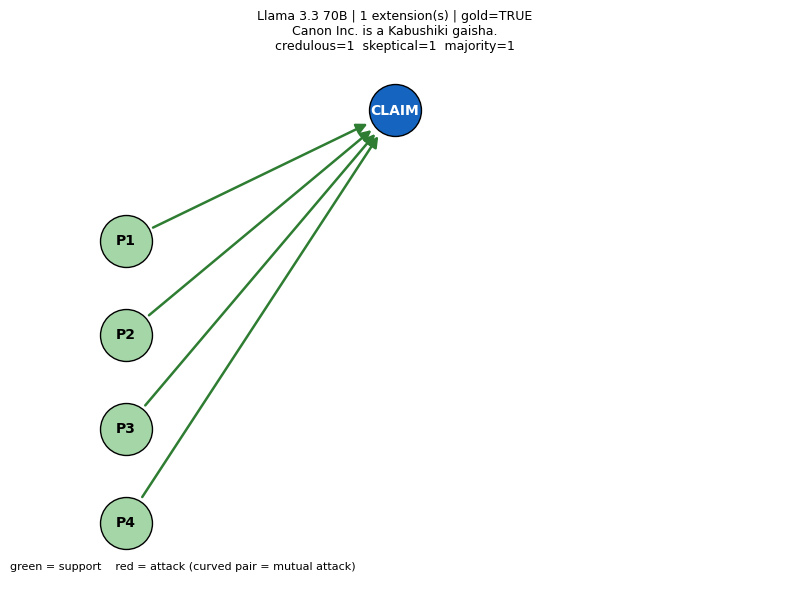


Claim: Canon Inc. is a Kabushiki gaisha.
  P1 [PRO]: Kabushiki gaisha means stock company
  P2 [PRO]: Listed on Tokyo Stock Exchange
  P3 [PRO]: Stock exchange listing implies joint-stock
  P4 [PRO]: Companies listed on stock exchanges are typically joint-stock
Extensions:
  {CLAIM, P1, P2, P3, P4}
saved: /kaggle/working/llama_graph_1ext.png
----------------------------------------------------------------------


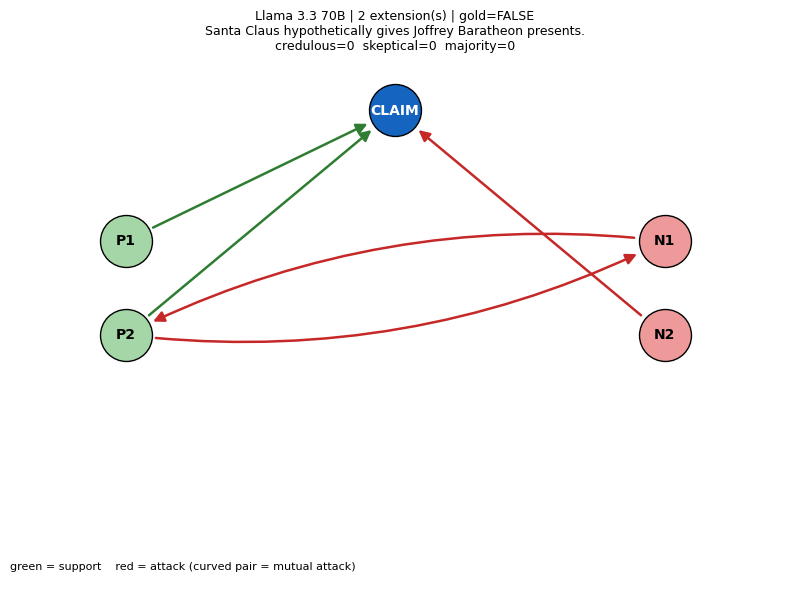


Claim: Santa Claus hypothetically gives Joffrey Baratheon presents.
  N1 [CON]: Joffrey's actions are evil, deserving coal
  N2 [CON]: Santa only gives presents to good children
  P1 [PRO]: Joffrey is a child
  P2 [PRO]: Santa gives presents to all children
Extensions:
  {N1, N2, P1}
  {N2, P1, P2}
saved: /kaggle/working/llama_graph_2ext.png
----------------------------------------------------------------------
no claim with 4 extension(s)
no claim with 8 extension(s)


In [7]:
import textwrap
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

LABEL = "Llama 3.3 70B"
PREFIX = "llama"
N_EXAMPLES = 10
res = load_ck()
res = [res[k] for k in sorted(res)]
print("claims available:", len(res))


def pos_of(nodes):
    pro = sorted(k for k in nodes if k.startswith("P"))
    con = sorted(k for k in nodes if k.startswith("N"))
    pos = {"CLAIM": (0.5, 0.9)}
    for i, k in enumerate(pro):
        pos[k] = (0.15, 0.65 - i * 0.18)
    for i, k in enumerate(con):
        pos[k] = (0.85, 0.65 - i * 0.18)
    return pos


def arrow(ax, a, b, color, rad=0.0):
    ax.add_patch(FancyArrowPatch(
        a, b, arrowstyle="-|>", mutation_scale=16, color=color,
        lw=1.8, shrinkA=22, shrinkB=22,
        connectionstyle=f"arc3,rad={rad}"))


def draw(r, fname):
    nodes = r["nodes"]
    pos = pos_of(nodes)
    sup = {tuple(e) for e in r["supports"]}
    direct = {tuple(e) for e in r["direct_attacks"]}
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlim(0, 1)
    ax.set_ylim(0.0, 1.0)
    ax.axis("off")
    for a, b in sup:
        arrow(ax, pos[a], pos[b], "#2e7d32")
    for a, b in direct:
        arrow(ax, pos[a], pos[b], "#c62828",
              rad=0.15 if (b, a) in direct else 0.0)
    colors = {"CLAIM": "#1565c0", "PRO": "#a5d6a7", "CON": "#ef9a9a"}
    for k, (x, y) in pos.items():
        ax.scatter(x, y, s=1400, c=colors[nodes[k]["role"]],
                   edgecolors="black", zorder=3)
        ax.text(x, y, k, ha="center", va="center", zorder=4,
                fontsize=10, fontweight="bold",
                color="white" if k == "CLAIM" else "black")
    dec = r["preferred_decisions"]
    ax.set_title(
        f"{LABEL} | {len(r['preferred_extensions'])} extension(s) | "
        f"gold={'TRUE' if r['gold'] else 'FALSE'}\n"
        f"{textwrap.fill(r['claim'], 80)}\n"
        f"credulous={dec['credulous']}  skeptical={dec['skeptical']}"
        f"  majority={dec['majority']}", fontsize=9)
    ax.text(0.0, 0.02, "green = support    red = attack "
            "(curved pair = mutual attack)", fontsize=8)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()
    print(f"\nClaim: {r['claim']}")
    for k in sorted(nodes):
        if k != "CLAIM":
            print(f"  {k} [{nodes[k]['role']}]: {nodes[k]['text']}")
    print("Extensions:")
    for e in r["preferred_extensions"]:
        print("  {" + ", ".join(e) + "}")
    print("saved:", fname)
    print("-" * 70)


for k in [1, 2, 4, 8]:
    found = [r for r in res if len(r["preferred_extensions"]) == k]
    if not found:
        print(f"no claim with {k} extension(s)")
        continue
    found.sort(key=lambda r: -len(r["nodes"]))
    draw(found[0], f"/kaggle/working/{PREFIX}_graph_{k}ext.png")